In [279]:
import numpy as np
import scipy as sp
import scipy.spatial
from collections import deque


class SandPile:
    """SandPile class"""

    def __init__(self, width, height, manna=False, seed=None):
        """Initialize a sandpile with the specified width and height."""
        self.width = width
        self.height = height
        self.manna = manna
        self.rng = np.random.default_rng(seed)
        
        if manna:
            self.threshold = 2
        else:
            self.threshold = 4

        self.grid = np.zeros((width, height), dtype=int)

        # We may want to keep track of the overall mass of the sand pile
        # overtime.  The following array will store the masses at each time
        # step (so that `len(self.mass_history)` is equal to the number of time
        # steps the sand pile has been running).
        self.mass_history = []
        # You probably will want to define other attributes to store statistics.

        # It is good practice to define *all* class attributes in the
        # `__init__` function, even if they get redefined later.  You may want
        # to define variables which are used to keep track of avalanches.
        self.grid_history = []
        

    def drop_sand(self, n=1, site=None):
        """Add `n` grains of sand to the grid.  Each grains of sand is added to
        a random site.

        This function also increments the time by 1 and update the internal
        `mass_history`.  Depending on how you want to code things, you may wish
        to also run the avalanche (alternatively, the avalanching might be
        executed elsewhere).

        Parameters
        ==========

        n: int

          The number of grains of sand of drop at this time step.  If left
          unspecified, defaults to 1.

        site:

          The site on which the grain(s) of sand should be dropped.  If `None`,
          a random site is used.

        """

        if site is None:
            coord = self.rng.integers(low = 0, high = [self.width, self.height])
            site = (int(coord[0]), int(coord[1]))
        
        x, y = site

        self.grid[x][y] += n

        #self.mass_history.append(self.mass())

        return site


    def mass(self):
        """Return the mass of the grid."""
        return np.sum(self.grid)

    def topple(self, site):
        """Topple the specified site."""
        x, y = site
        self.grid[x][y] -= 4
        loss = 4

        neighbours = ((x+1, y), (x-1, y), (x, y+1), (x, y-1))

        for neighbour in neighbours:
            nx, ny = neighbour
            if (0 <= nx < self.width) and (0 <= ny < self.height):
                self.grid[nx, ny] += 1
                loss -= 1

        return loss
    
    def topple_manna(self, site):
        """Topple the specified site according to the Manna model."""
        x, y = site
        self.grid[x][y] -= 2
        loss = 2

        neighbours = ((x+1, y), (x-1, y), (x, y+1), (x, y-1))

        to_topple = self.rng.choice(len(neighbours), 2, replace=True)

        for i in to_topple:
            nx, ny = neighbours[i]
            if (0 <= nx < self.width) and (0 <= ny < self.height):
                self.grid[nx][ny] += 1
                loss -= 1

        return loss
        

    def avalanche(self, start, record_history=False):
        """Stabilise the pile and return topples, area, loss and length."""

        topples = 0
        toppled_sites = set()
        loss = 0

        if self.manna:
            topple_func = self.topple_manna
        else:
            topple_func = self.topple

        if record_history:
            self.grid_history = [self.grid.copy()]

        unstable = deque()
        queued = set()

        # check if starting grid is unstable
        if self.grid[start] >= self.threshold:
            unstable.append(start)
            queued.add(start)

        while unstable:
            site = unstable.popleft()
            queued.discard(site)

            if self.grid[site] < self.threshold:
                continue

            loss += topple_func(site)
            topples += 1
            toppled_sites.add(site)

            if record_history:
                self.grid_history.append(self.grid.copy())

            x, y = site

            # only these sites can possibly be unstable
            affected_sites = ((x, y), (x+1, y), (x-1, y), (x, y+1), (x, y-1))

            for nx, ny in affected_sites:
                if (0 <= nx < self.width and 0 <= ny < self.height
                    and self.grid[nx, ny] >= self.threshold
                    and (nx, ny) not in queued):
                    unstable.append((nx, ny))
                    queued.add((nx, ny))

        area = len(toppled_sites)

        x0, y0 = start

        # L1 length
        length = max((abs(x - x0) + abs(y - y0) for x, y in toppled_sites), default=0)

        return topples, area, loss, length



In [280]:
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt

def simulate_avalanche(T, width=3, height=3, start_sites=None, manna=False, seed=None, return_mass=False):
    """
    Simulate an avalanche with length T, grid size = width * height
    Topple rule can be based on BTW model (base model) or manna model (extension)
    """
    pile = SandPile(width, height, manna=manna, seed=seed)
    results = np.zeros((T, 4))
    mass_history = np.zeros(T)

    if start_sites is not None and len(start_sites) > T:
        raise ValueError("The number of start sites cannot exceed T.")

    for t in range(T):
        if start_sites is not None and t < len(start_sites):
            start = pile.drop_sand(site=start_sites[t])
        else:
            start = pile.drop_sand()

        results[t] = pile.avalanche(start=start)
        mass_history[t] = pile.mass()

    if return_mass:
        return results, mass_history

    return results




def fit_exp(data):
    """
    fit exponential distribution for a single simulation
    for loss data
    """
    x, counts = np.unique(data, return_counts=True)

    # unconditional probability, including zero
    prob = counts / len(data)

    p_zero = np.mean(data == 0)

    # positive losses only
    fit_mask = x > 0

    x_fit = x[fit_mask]
    log_prob_fit = np.log(prob[fit_mask])

    slope, logA = np.polyfit(x_fit, log_prob_fit, 1)

    log_prob_pred = slope * x_fit + logA
    r2 = r2_score(log_prob_fit, log_prob_pred)

    decay_rate = -slope

    return {
        "x": x,
        "prob": prob,
        "x_fit": x_fit,
        "log_prob_pred": log_prob_pred,
        "p_zero": p_zero,
        "lambda": decay_rate,
        "logA": logA,
        "r2": r2
    }


def fit_exp_sim(sim_by_L, L_values, colname, print_res=True):
    """
    fit exponential distribution for a list of simulations 
    with different grid sizes
    """
    results = {}

    name_to_col = {
        "Loss": 2,
        "Length": 3
    }
    col = name_to_col[colname]

    for L in L_values:
        data = sim_by_L[L][:, col]

        result = fit_exp(data)
        results[L] = result

        if print_res:
            print(
                f"L={L}: "
                f"P({colname}=0)={result['p_zero']:.3f}, "
                f"lambda={result['lambda']:.3f}, "
                f"R²={result['r2']:.4f}"
            )

    return results


def plot_exp_sim(results, L_values, colname):
    """
    plot empirical distribution and fitted lines for loss
    """

    for i, L in enumerate(L_values):
        result = results[L]
        colour = f"C{i}"

        positive_mask = result["x"] > 0

        plt.scatter(
            result["x"][positive_mask],
            np.log(result["prob"][positive_mask]),
            s=15,
            color=colour,
            alpha=0.3
        )

        plt.plot(
            result["x_fit"],
            result["log_prob_pred"],
            color=colour,
            linewidth=2,
            label=(
                f"L={L}, "
                fr"$\lambda={result['lambda']:.2f}$"
            )
        )

    plt.xlabel(colname)
    plt.ylabel("Log probability")
    plt.title(f"Positive {colname} distributions")
    plt.legend()
    plt.tight_layout()
    plt.show()


def show_exp_diagnostic(L_values, results, colname):
    #fig, ax = plt.subplots()

    for i, L in enumerate(L_values):
        result = results[L]

        positive_mask = result["x"] > 0
        log_prob = np.log(result["prob"][positive_mask])
        residuals = log_prob - result["log_prob_pred"]

        plt.scatter(
            result["x_fit"],
            residuals,
            s=12,
            alpha=0.5,
            label=f"L={L}"
        )

    plt.axhline(0, color="black", linestyle="--", linewidth=1)
    plt.xlabel(colname)
    plt.ylabel(r"Residual in $\log P(x)$")
    plt.title(f"Residual plot for {colname}")
    plt.legend()



def select_powerlaw_cutoff(data, r2_threshold=0.95, min_points=10):
    """
    Select cutoff points for a single simulation
    based on survival function transformation
    and a lower bound r^2 value & minimum points inclusion
    """
    
    data = data[data > 0]
    x, counts = np.unique(data, return_counts=True)

    # compute survival function
    prob = 1- (counts.cumsum()-counts) / counts.sum()

    results = []

    # ensure that every fit contains at least min_points
    candidate_cutoffs = x[min_points - 1:]

    for cutoff in candidate_cutoffs:
        fit_mask = x <= cutoff

        log_x = np.log(x[fit_mask])
        log_prob = np.log(prob[fit_mask])

        alpha, logA = np.polyfit(log_x, log_prob, 1)

        log_prob_pred = alpha * log_x + logA
        r2 = r2_score(log_prob, log_prob_pred)

        results.append({
            "cutoff": cutoff,
            "alpha": alpha,
            "logA": logA,
            "r2": r2,
            "n_points": fit_mask.sum()
        })

    valid_results = [result for result in results if result["r2"] >= r2_threshold]

    if len(valid_results) == 0:
        return None, results

    selected = valid_results[-1]

    return selected, results


def select_cutoff_simulation(sim_by_L, L_values, colname, show_res=True, r2_threshold=0.95, min_points=10):
    """
    select cutoff points for a list of simulations with different grid sizes
    based of survival function transformation
    """
    cutoffs = {}

    name_to_col = {
        "Topples": 0,
        "Area": 1,
        "Length": 3
    }
    col = name_to_col[colname]

    for L in L_values:
        data = sim_by_L[L][:, col]

        selected, _ = select_powerlaw_cutoff(data, r2_threshold=r2_threshold, min_points=min_points)

        if selected is None:
            cutoffs[L] = None
            if show_res:
                print(f"L={L}: no valid cutoff found")
            continue

        cutoffs[L] = selected["cutoff"]

        if show_res:
            print(
                f"L={L}: "
                f"cutoff={selected['cutoff']}, "
                f"alpha={selected['alpha']:.3f}, "
                f"R²={selected['r2']:.4f}"
            )

    return cutoffs







def plot_raw_distribution(L_values, results, colname, adjustment=False, ax=None, n_bins=30, show_pts=False, fit_result=None):
    """
    plot empirical distribution for topples, area or length using log binning
    """

    name_to_col = {
        "Topples": 0,
        "Area": 1,
        "Length": 3
    }
    col = name_to_col[colname]

    if ax is None:
        _, ax = plt.subplots()


    # positive area/topples/length
    pos_by_L = {}

    for L in L_values:
        pos = results[L][:, col]
        pos_by_L[L] = pos[pos > 0]

    # bins
    maximum = max(pos.max() for pos in pos_by_L.values())

    # log bin edges
    bin_edges = np.unique(np.floor(np.geomspace(1, maximum + 1, n_bins + 1)).astype(int))

    if bin_edges[-1] <= maximum:
        bin_edges = np.append(bin_edges, maximum + 1)


    for i, L in enumerate(L_values):
        pos = pos_by_L[L]

        # unbinned empirical pmf
        if show_pts:
            x_raw, raw_counts = np.unique(pos, return_counts=True)
            raw_prob = raw_counts / len(pos)

            if adjustment:
                N = L**2
                raw_prob = np.log(N) * raw_prob

            ax.scatter(x_raw, raw_prob, s=8, alpha=0.15, edgecolors="none")

        # log binned empirical pmf
        counts, edges = np.histogram(pos, bins=bin_edges)
        widths = np.diff(edges)

        # geometric centres
        centres = np.sqrt(edges[:-1] * edges[1:])

        # empirical probability 
        probability_density = counts / (len(pos) * widths)

        if adjustment:
            N = L**2
            probability_density = (np.log(N) * probability_density)

        nonempty = counts > 0

        ax.plot(
            centres[nonempty],
            probability_density[nonempty],
            color=f"C{i}",
            linewidth=2,
            label=f"L={L}"
        )


    # plot the fitted line
    if fit_result is not None:
        slope = fit_result["slope"]
        intercept = fit_result["intercept"]
        tau = -slope

        x_fit = np.geomspace(fit_result["fit_x_min"], fit_result["fit_x_max"], 200)
        y_fit = (np.exp(intercept)* x_fit**slope)

        ax.plot(x_fit, y_fit, color="black", linestyle="--", alpha=0.6, linewidth=2, label=fr"$\alpha={tau:.2f}$")

    ax.set_xscale("log")
    ax.set_yscale("log")

    ax.set_xlabel(colname)

    if adjustment:
        ax.set_ylabel(r"$\log(N)\,P(" + colname + r")$")
        ax.set_title(
            colname
            + r" distributions with $\log(N)$ scaling for different system sizes (L)")
    else:
        ax.set_ylabel(r"$P(" + colname + r")$")
        ax.set_title(colname + " distributions for different system sizes (L)")
    
    ax.legend()

    return ax




def collapse_deviation(L_values, cutoffs, results, colname, lower_cutoffs=None, show_res=True, adjusted=False):
    """
    calculates the fitted line to the collapse
    """
    
    name_to_col = {
        "Topples": 0,
        "Area": 1,
        "Length": 3
    }
    col = name_to_col[colname]

    data_by_L = {}
    all_log_x = []
    all_log_prob = []

    for L in L_values:
        pos = results[L][:, col]
        pos = pos[pos > 0]

        x, counts = np.unique(pos, return_counts=True)
        prob = counts / counts.sum()

        # select scaling region
        if lower_cutoffs is None:
            fit_mask = x <= cutoffs[L]
        else:
            fit_mask = ((x >= lower_cutoffs[L]) & (x <= cutoffs[L]))

        log_x = np.log(x[fit_mask])
        log_prob = np.log(prob[fit_mask])

        if adjusted:
            N = L**2

            # log((log N)P)
            log_prob = (log_prob+np.log(np.log(N)))

        data_by_L[L] = (log_x, log_prob)
        all_log_x.append(log_x)
        all_log_prob.append(log_prob)

    all_log_x = np.concatenate(all_log_x)
    all_log_prob = np.concatenate(all_log_prob)

    slope, intercept = np.polyfit(all_log_x, all_log_prob, 1)

    maximum_deviation_by_L = {}
    rmse_by_L = {}
    all_residuals = []

    for L, (log_x, log_prob) in data_by_L.items():
        fitted = slope * log_x + intercept
        residuals = log_prob - fitted

        maximum_deviation_by_L[L] = np.max(np.abs(residuals))
        rmse_by_L[L] = np.sqrt(np.mean(residuals**2))

        all_residuals.append(residuals)

    all_residuals = np.concatenate(all_residuals)

    overall_maximum = np.max(np.abs(all_residuals))
    overall_rmse = np.sqrt(np.mean(all_residuals**2))

    if show_res:
        if adjusted:
            print("After log(N) scaling")
        else:
            print("Before log(N) scaling")
        print(f"Slope: {slope:.3f}")

        for L in L_values:
            print(f"  L={L}: maximum={maximum_deviation_by_L[L]:.3f}")
        print(f"Overall maximum deviation: {overall_maximum:.3f}")
        print(f"Overall RMSE: {overall_rmse:.3f}")

    return {
        "slope": slope,
        "intercept": intercept,
        "fit_x_min": np.exp(all_log_x.min()),
        "fit_x_max": np.exp(all_log_x.max()),
        "maximum_by_L": maximum_deviation_by_L,
        "overall_maximum": overall_maximum,
        "overall_rmse": overall_rmse
    }


def get_lower_cutoff(L_values, results, colname, n_bins=30, bins_to_exclude=1):
    """
    return the bin edge after excluding the specified
    number of initial log bins.
    """

    name_to_col = {
        "Topples": 0,
        "Area": 1,
        "Length": 3
    }
    col = name_to_col[colname]

    pos_by_L = {}

    for L in L_values:
        pos = results[L][:, col]
        pos_by_L[L] = pos[pos > 0]

    maximum = max(
        pos.max() for pos in pos_by_L.values()
    )

    bin_edges = np.unique(
        np.floor(
            np.geomspace(
                1,
                maximum + 1,
                n_bins + 1
            )
        ).astype(int)
    )

    if bin_edges[-1] <= maximum:
        bin_edges = np.append(
            bin_edges,
            maximum + 1
        )

    if bins_to_exclude >= len(bin_edges) - 1:
        raise ValueError("Too many bins have been excluded.")

    return bin_edges[bins_to_exclude]


### Base model

In [299]:
results, mass_history = simulate_avalanche(
    T=55000,
    width=50,
    height=50,
    manna=False,
    seed=12345,
    return_mass=True
)

average_height = mass_history / (50 * 50)

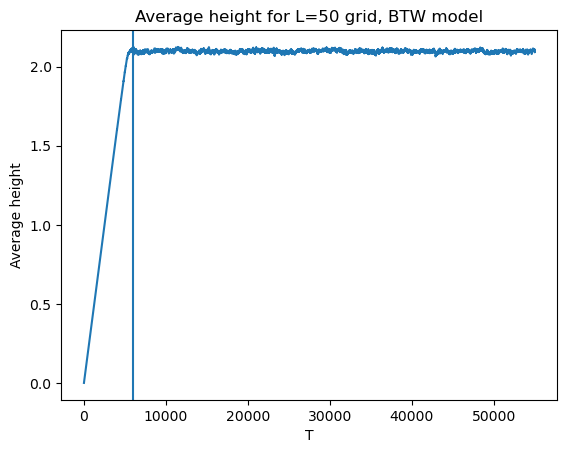

In [307]:
plt.plot(range(55000), average_height)
plt.axvline(6000)
plt.xlabel("T")
plt.ylabel("Average height")
plt.title("Average height for L=50 grid, BTW model")
plt.show()

In [181]:
# BTW model 
L_values = [10, 20, 30, 40, 50]
results_by_L = {}
burn_in = 5000

for L in L_values:
    results_by_L[L] = simulate_avalanche(T=55000, width=L, height=L, manna=False, seed=12345)
    results_by_L[L] = results_by_L[L][burn_in:, :]


In [174]:
result_1 = simulate_avalanche(
    T=1000,
    width=20,
    height=20,
    manna=False,
    seed=12345
)

result_2 = simulate_avalanche(
    T=1000,
    width=20,
    height=20,
    manna=False,
    seed=12345
)

print(np.array_equal(result_1, result_2))

True


#### Area

In [182]:
# cutoff points for each grid with size L

area_cutoffs = select_cutoff_simulation(results_by_L, L_values, "Area")

L=10: cutoff=26.0, alpha=-0.583, R²=0.9524
L=20: cutoff=77.0, alpha=-0.467, R²=0.9507
L=30: cutoff=175.0, alpha=-0.451, R²=0.9503
L=40: cutoff=265.0, alpha=-0.420, R²=0.9501
L=50: cutoff=422.0, alpha=-0.416, R²=0.9501


In [183]:
collapse_area_before = collapse_deviation(L_values, area_cutoffs, results_by_L, "Area", adjusted=False)

Before log(N) scaling
Slope: -1.105
  L=10: maximum=0.402
  L=20: maximum=0.554
  L=30: maximum=0.592
  L=40: maximum=0.990
  L=50: maximum=1.281
Overall maximum deviation: 1.281
Overall RMSE: 0.275


In [184]:
collapse_area_after = collapse_deviation(L_values, area_cutoffs, results_by_L, "Area", adjusted=True)

After log(N) scaling
Slope: -1.054
  L=10: maximum=0.277
  L=20: maximum=0.379
  L=30: maximum=0.601
  L=40: maximum=1.018
  L=50: maximum=1.270
Overall maximum deviation: 1.270
Overall RMSE: 0.260


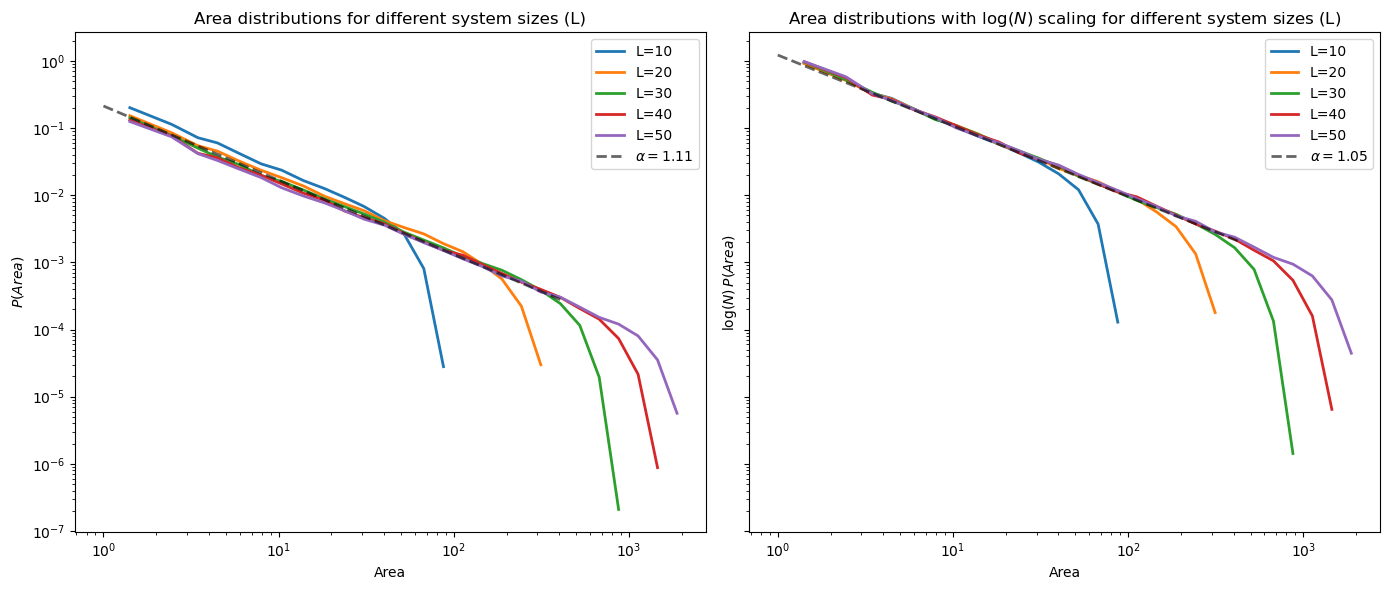

In [232]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

plot_raw_distribution(L_values, results_by_L, "Area", adjustment=False, ax=axes[0], fit_result=collapse_area_before)
plot_raw_distribution(L_values, results_by_L, "Area", adjustment=True, ax=axes[1], fit_result=collapse_area_after)

fig.tight_layout()
plt.show()

#### Topples

In [187]:
topples_cutoffs = select_cutoff_simulation(results_by_L, L_values, "Topples")

L=10: cutoff=28.0, alpha=-0.591, R²=0.9517
L=20: cutoff=89.0, alpha=-0.473, R²=0.9505
L=30: cutoff=211.0, alpha=-0.456, R²=0.9501
L=40: cutoff=339.0, alpha=-0.428, R²=0.9501
L=50: cutoff=533.0, alpha=-0.419, R²=0.9500


In [189]:
collapse_topples_before = collapse_deviation(L_values, topples_cutoffs, results_by_L, "Topples", adjusted=False)

Before log(N) scaling
Slope: -1.114
  L=10: maximum=0.460
  L=20: maximum=0.548
  L=30: maximum=0.655
  L=40: maximum=1.137
  L=50: maximum=1.909
Overall maximum deviation: 1.909
Overall RMSE: 0.307


In [191]:
collapse_topples_after = collapse_deviation(L_values, topples_cutoffs, results_by_L, "Topples", adjusted=True)

After log(N) scaling
Slope: -1.065
  L=10: maximum=0.287
  L=20: maximum=0.386
  L=30: maximum=0.743
  L=40: maximum=1.111
  L=50: maximum=1.888
Overall maximum deviation: 1.888
Overall RMSE: 0.295


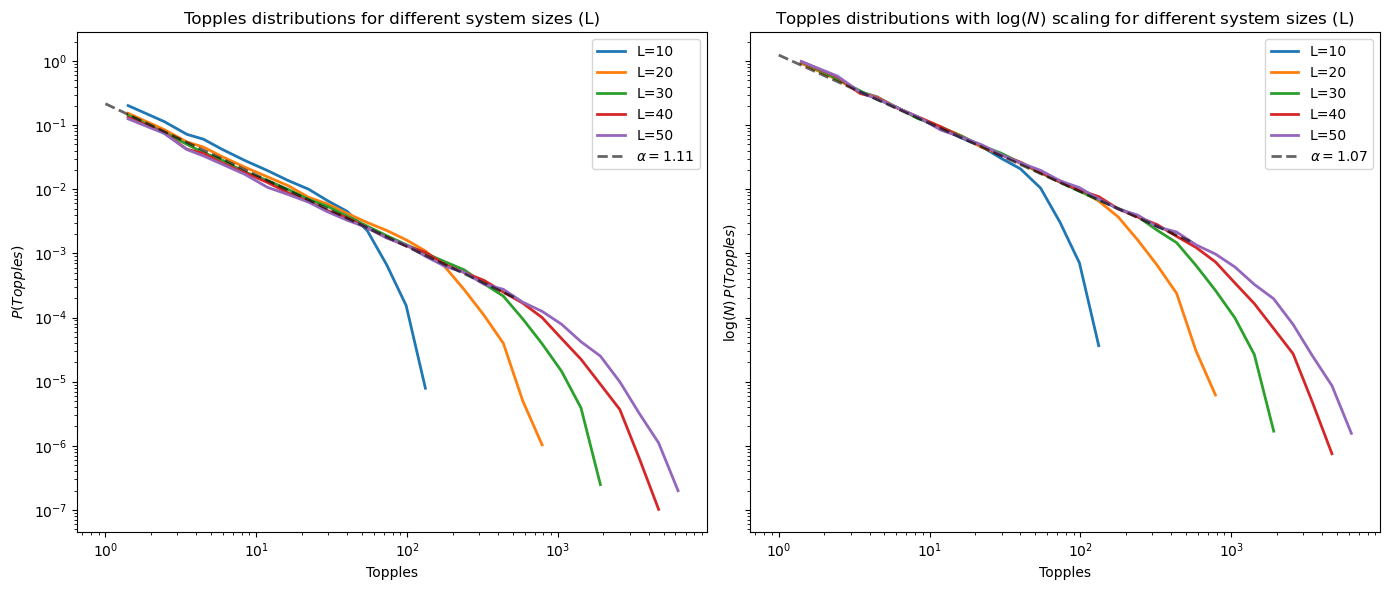

In [192]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

plot_raw_distribution(L_values, results_by_L, "Topples", adjustment=False, ax=axes[0], fit_result=collapse_topples_before)
plot_raw_distribution(L_values, results_by_L, "Topples", adjustment=True, ax=axes[1], fit_result=collapse_topples_after)

fig.tight_layout()
plt.show()

#### Loss

In [217]:
loss_results = fit_exp_sim(results_by_L, L_values, "Loss")

L=10: P(Loss=0)=0.723, lambda=0.321, R²=0.9895
L=20: P(Loss=0)=0.767, lambda=0.226, R²=0.9591
L=30: P(Loss=0)=0.792, lambda=0.164, R²=0.9311
L=40: P(Loss=0)=0.816, lambda=0.135, R²=0.9117
L=50: P(Loss=0)=0.827, lambda=0.134, R²=0.9169


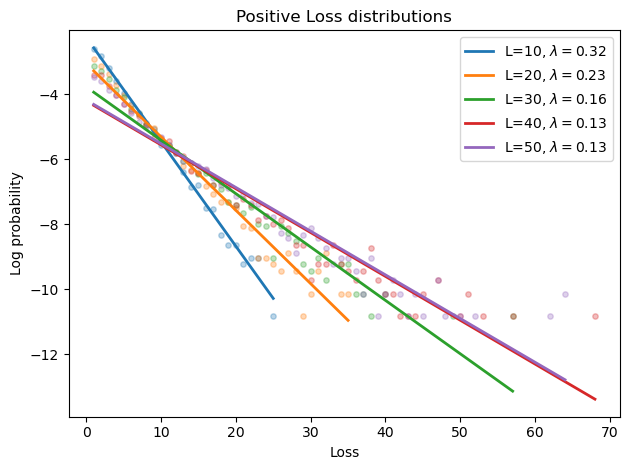

In [241]:
plot_exp_sim(loss_results, L_values, "Loss")

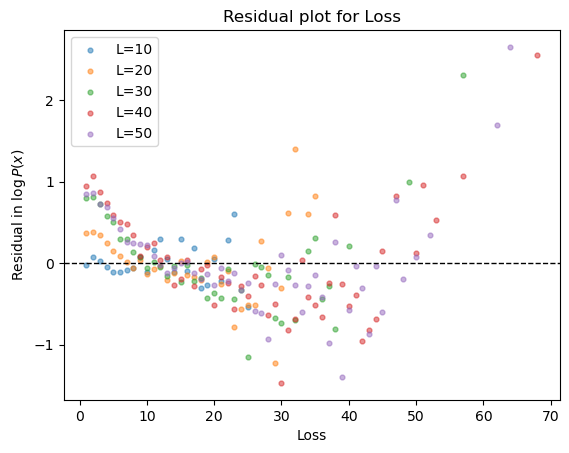

In [257]:
show_exp_diagnostic(L_values, loss_results, "Loss")

#### Length

##### Power law

In [197]:
L_values = [10,20,30,40,50]

length_cutoffs = select_cutoff_simulation(results_by_L, L_values, "Length", min_points=8, r2_threshold=0.88)

L=10: cutoff=8.0, alpha=-0.772, R²=0.8806
L=20: cutoff=15.0, alpha=-0.674, R²=0.8856
L=30: cutoff=24.0, alpha=-0.693, R²=0.8800
L=40: cutoff=32.0, alpha=-0.682, R²=0.8829
L=50: cutoff=40.0, alpha=-0.674, R²=0.8820


In [198]:
collapse_length_before = collapse_deviation(L_values, length_cutoffs, results_by_L, "Length", adjusted=False)

Before log(N) scaling
Slope: -0.882
  L=10: maximum=0.604
  L=20: maximum=0.530
  L=30: maximum=0.646
  L=40: maximum=0.702
  L=50: maximum=0.733
Overall maximum deviation: 0.733
Overall RMSE: 0.223


In [199]:
collapse_length_after = collapse_deviation(L_values, length_cutoffs, results_by_L, "Length", adjusted=True)

After log(N) scaling
Slope: -0.814
  L=10: maximum=0.449
  L=20: maximum=0.522
  L=30: maximum=0.511
  L=40: maximum=0.485
  L=50: maximum=0.458
Overall maximum deviation: 0.522
Overall RMSE: 0.151


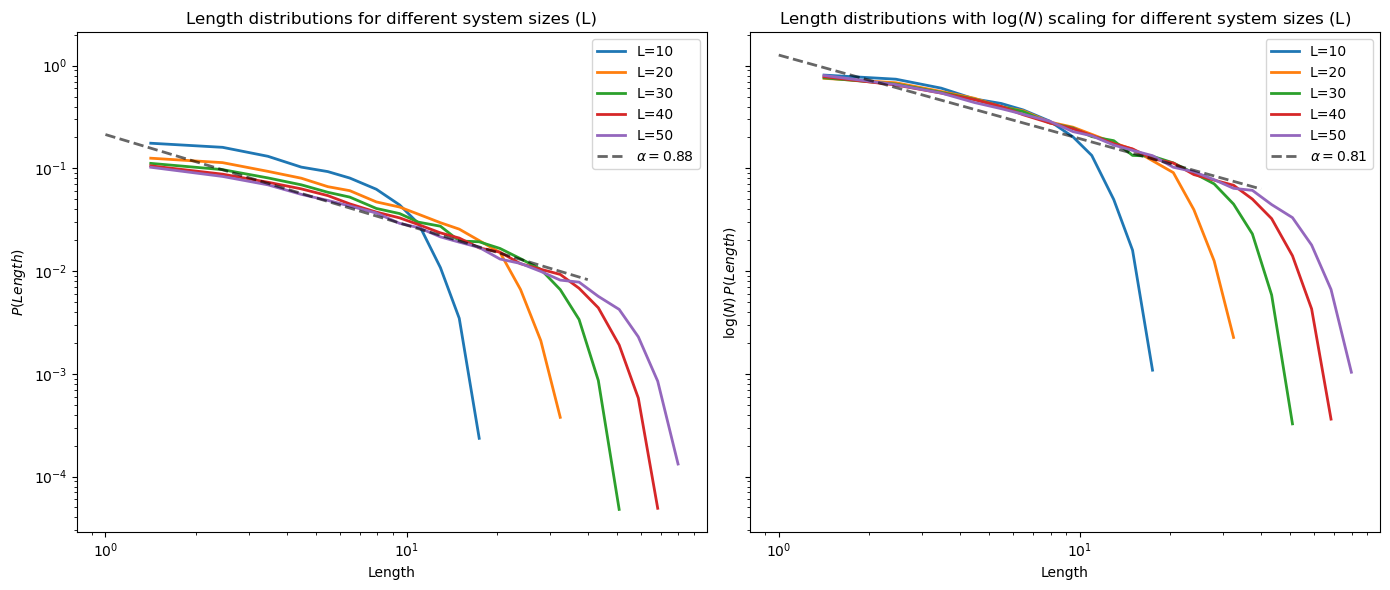

In [200]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

plot_raw_distribution(L_values, results_by_L, "Length", adjustment=False, ax=axes[0], fit_result=collapse_length_before)
plot_raw_distribution(L_values, results_by_L, "Length", adjustment=True, ax=axes[1], fit_result=collapse_length_after)

fig.tight_layout()
plt.show()

##### Exponential

In [219]:
length_results = fit_exp_sim(results_by_L, L_values, "Length")

L=10: P(Length=0)=0.689, lambda=0.421, R²=0.8597
L=20: P(Length=0)=0.650, lambda=0.174, R²=0.9129
L=30: P(Length=0)=0.635, lambda=0.124, R²=0.8927
L=40: P(Length=0)=0.630, lambda=0.094, R²=0.9076
L=50: P(Length=0)=0.623, lambda=0.069, R²=0.9169


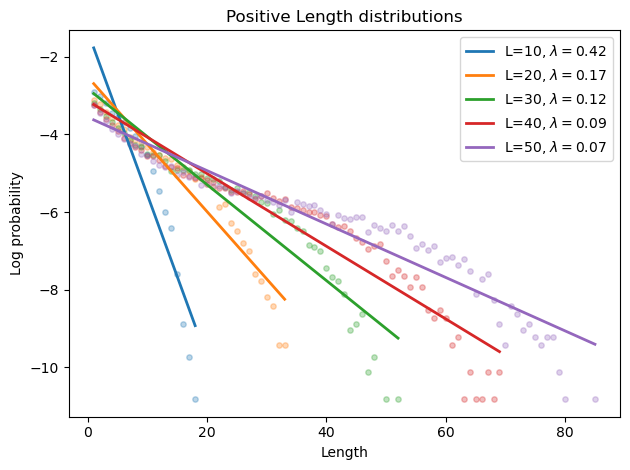

In [242]:
plot_exp_sim(length_results, L_values, "Length")

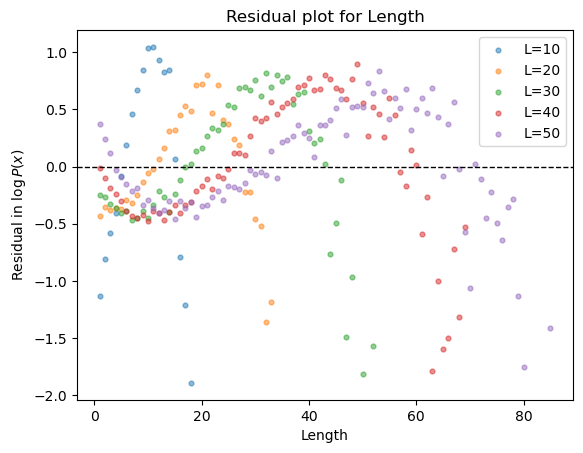

In [258]:
show_exp_diagnostic(L_values, length_results, "Length")

### Manna model

In [ ]:
results_manna, mass_history_manna = simulate_avalanche(
    T=55000,
    width=50,
    height=50,
    manna=True,
    seed=12345,
    return_mass=True
)

In [296]:
average_height_manna = mass_history_manna / (50 * 50)

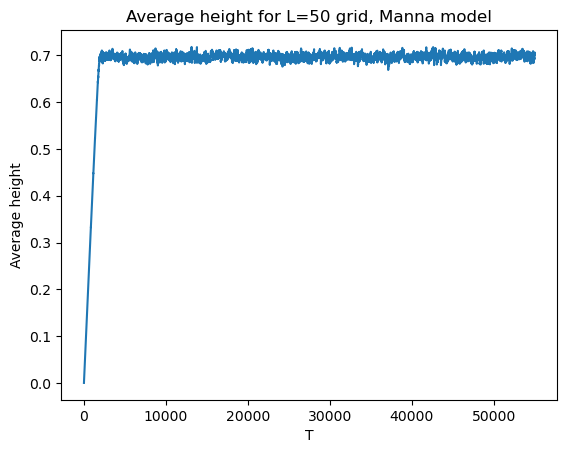

In [298]:
plt.plot(range(55000), average_height_manna)
plt.xlabel("T")
plt.ylabel("Average height")
plt.title("Average height for L=50 grid, Manna model")
plt.show()

In [201]:
# manna model 
L_values = [10, 20, 30, 40, 50]
results_by_L_manna = {}
burn_in = 5000

for L in L_values:
    results_by_L_manna[L] = simulate_avalanche(T=55000, width=L, height=L, manna=True, seed=12345)
    results_by_L_manna[L] = results_by_L_manna[L][burn_in:, :]

#### Area

In [203]:
area_cutoffs_manna = select_cutoff_simulation(results_by_L_manna, L_values, "Area")

L=10: cutoff=23.0, alpha=-0.693, R²=0.9510
L=20: cutoff=100.0, alpha=-0.688, R²=0.9502
L=30: cutoff=246.0, alpha=-0.702, R²=0.9501
L=40: cutoff=478.0, alpha=-0.714, R²=0.9500
L=50: cutoff=721.0, alpha=-0.699, R²=0.9501


In [204]:
collapse_area_before_manna = collapse_deviation(L_values, area_cutoffs_manna, results_by_L, "Area", adjusted=False)

Before log(N) scaling
Slope: -1.125
  L=10: maximum=0.374
  L=20: maximum=0.551
  L=30: maximum=0.667
  L=40: maximum=1.616
  L=50: maximum=1.679
Overall maximum deviation: 1.679
Overall RMSE: 0.365


In [205]:
collapse_area_after_manna = collapse_deviation(L_values, area_cutoffs_manna, results_by_L, "Area", adjusted=True)

After log(N) scaling
Slope: -1.081
  L=10: maximum=0.386
  L=20: maximum=0.402
  L=30: maximum=0.582
  L=40: maximum=1.655
  L=50: maximum=1.656
Overall maximum deviation: 1.656
Overall RMSE: 0.357


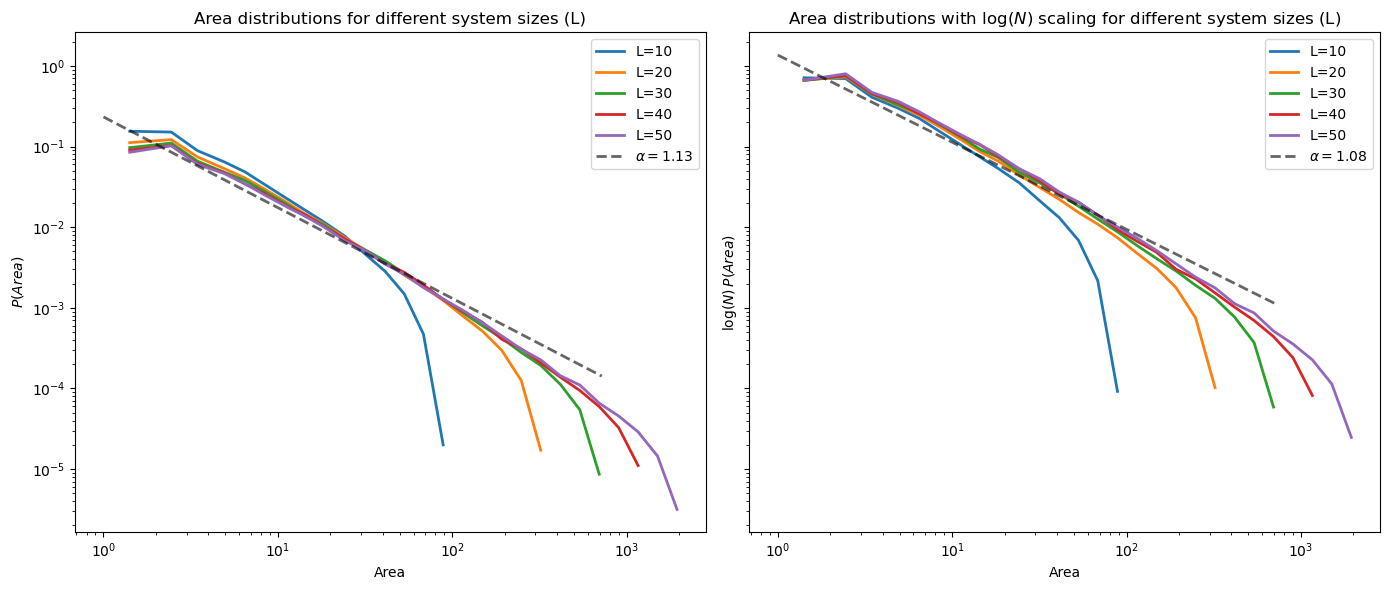

In [278]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

plot_raw_distribution(L_values, results_by_L_manna, "Area", adjustment=False, ax=axes[0], fit_result=collapse_area_before_manna)
plot_raw_distribution(L_values, results_by_L_manna, "Area", adjustment=True, ax=axes[1], fit_result=collapse_area_after_manna)

fig.tight_layout()
plt.show()

In [277]:
L_values=[10,20,30,40,50]
lower_cutoff_area_manna = get_lower_cutoff(L_values, results_by_L_manna, "Area", n_bins=30, bins_to_exclude=1)
lower_cutoffs_area_manna = {L: lower_cutoff_area_manna for L in L_values}

collapse_area_before_manna_refit = collapse_deviation(L_values, area_cutoffs_manna, results_by_L, 
                                                    "Area", lower_cutoffs=lower_cutoffs_area_manna, adjusted=False)

collapse_area_after_manna_refit = collapse_deviation(L_values, area_cutoffs_manna, results_by_L, 
                                                    "Area", lower_cutoffs=lower_cutoffs_area_manna, adjusted=True)


Before log(N) scaling
Slope: -1.131
  L=10: maximum=0.361
  L=20: maximum=0.544
  L=30: maximum=0.667
  L=40: maximum=1.612
  L=50: maximum=1.674
Overall maximum deviation: 1.674
Overall RMSE: 0.365
After log(N) scaling
Slope: -1.086
  L=10: maximum=0.250
  L=20: maximum=0.407
  L=30: maximum=0.582
  L=40: maximum=1.651
  L=50: maximum=1.653
Overall maximum deviation: 1.653
Overall RMSE: 0.357


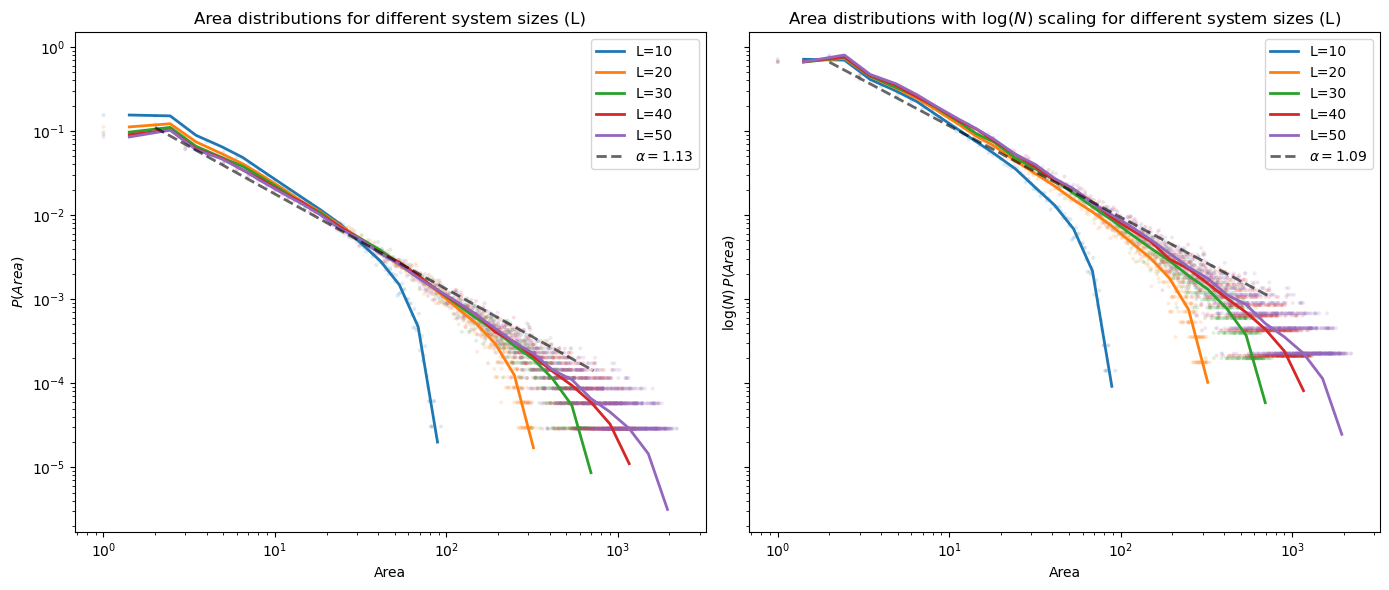

In [289]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

plot_raw_distribution(L_values, results_by_L_manna, "Area", adjustment=False, ax=axes[0], show_pts=True, fit_result=collapse_area_before_manna_refit)
plot_raw_distribution(L_values, results_by_L_manna, "Area", adjustment=True, ax=axes[1], show_pts=True, fit_result=collapse_area_after_manna_refit)

fig.tight_layout()
plt.show()

#### Topples

In [207]:
topples_cutoffs_manna = select_cutoff_simulation(results_by_L_manna, L_values, "Topples")

L=10: cutoff=47.0, alpha=-0.713, R²=0.9502
L=20: cutoff=261.0, alpha=-0.676, R²=0.9501
L=30: cutoff=870.0, alpha=-0.696, R²=0.9500
L=40: cutoff=1947.0, alpha=-0.680, R²=0.9500
L=50: cutoff=3288.0, alpha=-0.647, R²=0.9500


In [208]:
collapse_topples_before_manna = collapse_deviation(L_values, topples_cutoffs_manna, results_by_L, "Topples", adjusted=False)
collapse_topples_after_manna = collapse_deviation(L_values, topples_cutoffs_manna, results_by_L, "Topples", adjusted=True)

Before log(N) scaling
Slope: -1.123
  L=10: maximum=0.532
  L=20: maximum=1.486
  L=30: maximum=1.628
  L=40: maximum=1.545
  L=50: maximum=1.816
Overall maximum deviation: 1.816
Overall RMSE: 0.479
After log(N) scaling
Slope: -1.085
  L=10: maximum=0.330
  L=20: maximum=1.662
  L=30: maximum=1.697
  L=40: maximum=1.536
  L=50: maximum=1.738
Overall maximum deviation: 1.738
Overall RMSE: 0.492


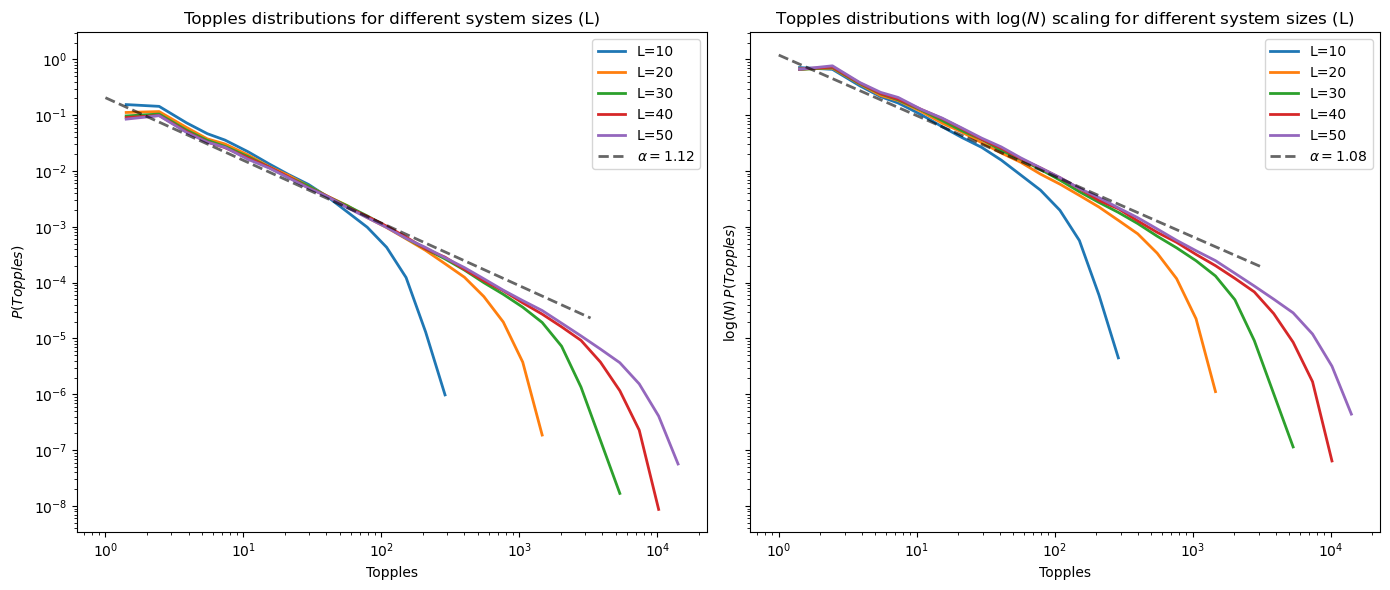

In [209]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

plot_raw_distribution(L_values, results_by_L_manna, "Topples", adjustment=False, ax=axes[0], fit_result=collapse_topples_before_manna)
plot_raw_distribution(L_values, results_by_L_manna, "Topples", adjustment=True, ax=axes[1], fit_result=collapse_topples_after_manna)

fig.tight_layout()
plt.show()

#### Loss

In [223]:
loss_results_manna = fit_exp_sim(results_by_L_manna, L_values, "Loss")

L=10: P(Loss=0)=0.589, lambda=0.474, R²=0.9936
L=20: P(Loss=0)=0.676, lambda=0.252, R²=0.9387
L=30: P(Loss=0)=0.724, lambda=0.199, R²=0.9520
L=40: P(Loss=0)=0.758, lambda=0.145, R²=0.9304
L=50: P(Loss=0)=0.785, lambda=0.118, R²=0.9019


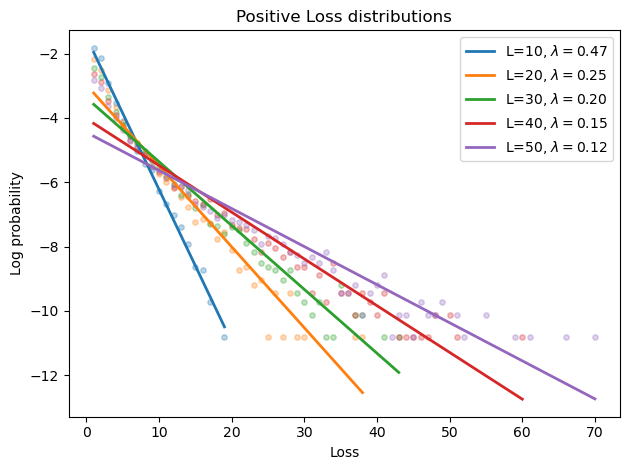

In [243]:
plot_exp_sim(loss_results_manna, L_values, "Loss")

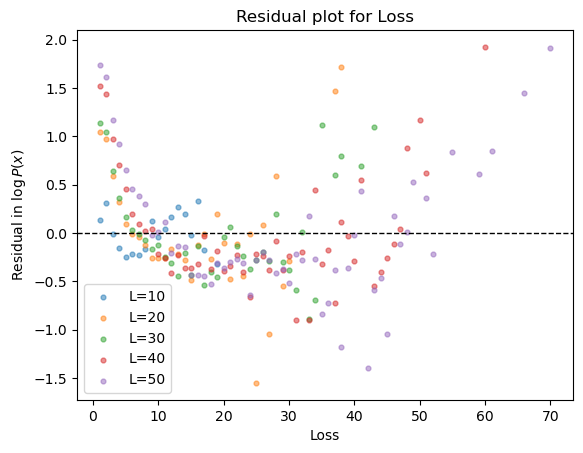

In [267]:
show_exp_diagnostic(L_values, loss_results_manna, "Loss")

#### Length

##### Power law

In [212]:
length_cutoffs_manna = select_cutoff_simulation(results_by_L_manna, L_values, "Length", min_points=8, r2_threshold=0.88)

L=10: cutoff=8.0, alpha=-0.895, R²=0.8898
L=20: cutoff=18.0, alpha=-0.990, R²=0.8808
L=30: cutoff=28.0, alpha=-1.031, R²=0.8818
L=40: cutoff=39.0, alpha=-1.075, R²=0.8821
L=50: cutoff=50.0, alpha=-1.115, R²=0.8828


In [213]:
collapse_length_before_manna = collapse_deviation(L_values, length_cutoffs_manna, results_by_L, "Length", adjusted=False)
collapse_length_after_manna = collapse_deviation(L_values, length_cutoffs_manna, results_by_L, "Length", adjusted=True)

Before log(N) scaling
Slope: -0.932
  L=10: maximum=0.602
  L=20: maximum=0.623
  L=30: maximum=0.739
  L=40: maximum=0.795
  L=50: maximum=0.826
Overall maximum deviation: 0.826
Overall RMSE: 0.230
After log(N) scaling
Slope: -0.867
  L=10: maximum=0.543
  L=20: maximum=0.615
  L=30: maximum=0.604
  L=40: maximum=0.578
  L=50: maximum=0.551
Overall maximum deviation: 0.615
Overall RMSE: 0.172


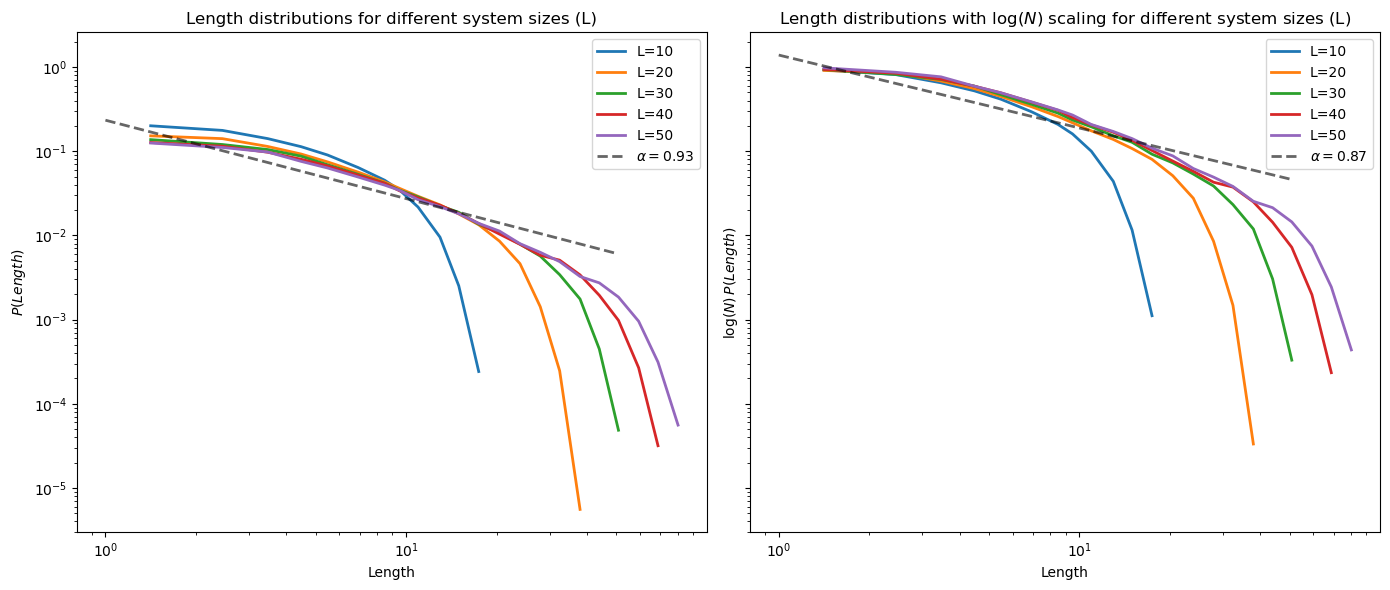

In [214]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

plot_raw_distribution(L_values, results_by_L_manna, "Length", adjustment=False, ax=axes[0], fit_result=collapse_length_before_manna)
plot_raw_distribution(L_values, results_by_L_manna, "Length", adjustment=True, ax=axes[1], fit_result=collapse_length_after_manna)

fig.tight_layout()
plt.show()

##### Exponential

In [221]:
length_results_manna = fit_exp_sim(results_by_L_manna, L_values, "Length")

L=10: P(Length=0)=0.448, lambda=0.390, R²=0.9043
L=20: P(Length=0)=0.399, lambda=0.219, R²=0.9090
L=30: P(Length=0)=0.381, lambda=0.138, R²=0.9510
L=40: P(Length=0)=0.369, lambda=0.104, R²=0.9518
L=50: P(Length=0)=0.365, lambda=0.085, R²=0.9603


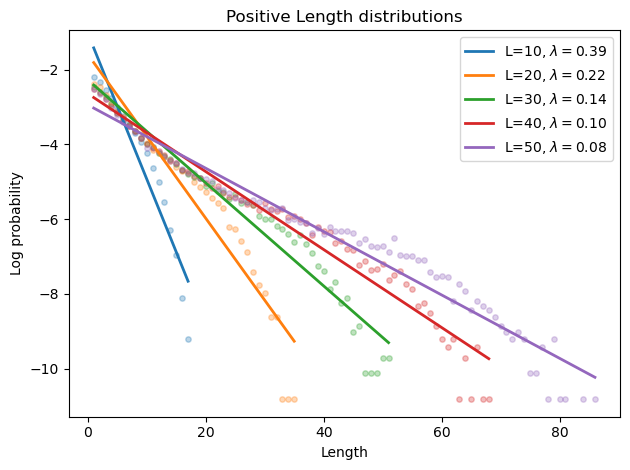

In [244]:
plot_exp_sim(length_results_manna, L_values, "Length")

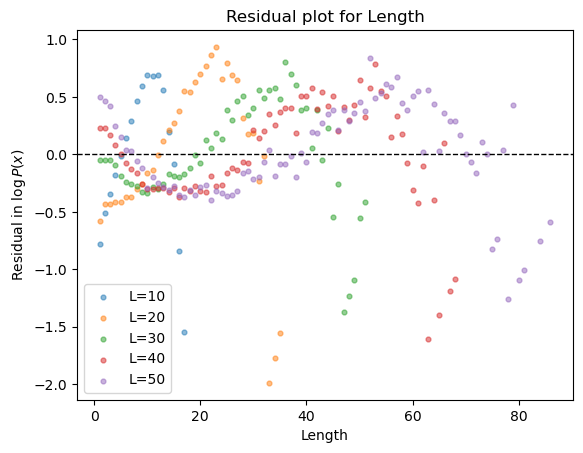

In [261]:
show_exp_diagnostic(L_values, length_results_manna, "Length")